# Data Understanding

A first pass over the nine raw Olist CSVs: what each file contains, what one row represents,
how the tables relate, and which defects will constrain the analysis that follows.

## Objective

Establish a verified, evidence-backed understanding of the data before any cleaning, ETL or
modelling work begins. Concretely:

1. Inventory every file (size, shape, memory, duplicate rows).
2. Profile every column (dtype, nulls, cardinality).
3. Quantify missing values and explain their **business meaning**.
4. Confirm the **grain** and **primary key** of every table with code, not assumption.
5. Verify **referential integrity** for every foreign key and document the relationship model.
6. Produce a **data dictionary** for all nine tables.
7. Investigate and quantify **data-quality issues** that will constrain cleaning and modelling.
8. State how many orders are eligible for training labels.

## Datasets

| # | File | Rows (expected) | Grain |
|---|------|-----------------|-------|
| 1 | `olist_orders_dataset.csv` | ~99k | 1 row per order |
| 2 | `olist_order_items_dataset.csv` | ~112k | 1 row per order line item |
| 3 | `olist_order_payments_dataset.csv` | ~104k | 1 row per payment line |
| 4 | `olist_order_reviews_dataset.csv` | ~99k | 1 row per review (can exceed 1 per order) |
| 5 | `olist_customers_dataset.csv` | ~99k | 1 row per order-scoped customer |
| 6 | `olist_sellers_dataset.csv` | ~3k | 1 row per seller |
| 7 | `olist_products_dataset.csv` | ~33k | 1 row per product |
| 8 | `olist_geolocation_dataset.csv` | ~1M | many rows per ZIP prefix |
| 9 | `product_category_name_translation.csv` | ~71 | 1 row per category |

## Data source and safety

All raw files live in **`data/`** at the repository root. This directory is
**READ ONLY** — nothing in this notebook writes to, moves, or modifies it. Every cell below
only calls `pd.read_csv`. Derived artefacts belong in `data/interim/` and `data/processed/`.

## Scope

This notebook describes data quality only. It does **not** build model features. Post-purchase
fields (`order_delivered_customer_date`, `order_delivered_carrier_date`, `order_approved_at`,
`review_score`, `order_status`) are inspected here **solely to characterise data quality** —
they are not model inputs.

## 0. Setup

Project root is resolved by walking **upwards from the notebook's own location** until the
marker files `data/` and `pyproject.toml` are found. This makes the notebook independent of the
working directory it is launched from.

In [1]:
from __future__ import annotations

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")


def notebook_dir() -> Path:
    # __file__ exists when the notebook is executed as a script; otherwise fall back to CWD,
    # which Jupyter/nbconvert sets to the notebook's directory.
    try:
        return Path(__file__).resolve().parent
    except NameError:
        return Path.cwd().resolve()


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() and (candidate / "pyproject.toml").is_file():
            return candidate
    raise RuntimeError(f"Could not locate project root (data/ + pyproject.toml) from {start}")


PROJECT_ROOT = find_project_root(notebook_dir())
DATA_DIR = PROJECT_ROOT / "data"

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 250)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print(f"pandas  {pd.__version__}")
print(f"numpy   {np.__version__}")
print(f"PROJECT_ROOT = {PROJECT_ROOT}")
print(f"DATA_DIR     = {DATA_DIR}")
print(f"CSV files    = {len(list(DATA_DIR.glob('*.csv')))}")


pandas  3.1.0
numpy   2.5.4
PROJECT_ROOT = D:\reps\olist-intelligence
DATA_DIR     = D:\reps\olist-intelligence\data
CSV files    = 9


## 1. Inventory

**Question:** what exactly do we have — how big is each file, how many rows and columns, how
much memory does it need, and are there fully duplicated rows?

All nine files are loaded once here and reused for the rest of the notebook. Timestamps are
kept as raw strings at this stage so that the dtype profile in Section 2 reflects what is
actually on disk; they are parsed explicitly where temporal analysis is needed.

In [2]:
FILES = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

tables: dict[str, pd.DataFrame] = {}
for name, fname in FILES.items():
    path = DATA_DIR / fname
    assert path.is_file(), f"missing raw file: {path}"
    tables[name] = pd.read_csv(path)

inventory = pd.DataFrame(
    [
        {
            "table": name,
            "file": FILES[name],
            "rows": len(df),
            "columns": df.shape[1],
            "memory_mb": round(df.memory_usage(deep=True).sum() / 1024**2, 2),
            "duplicate_rows": int(df.duplicated().sum()),
        }
        for name, df in tables.items()
    ]
).sort_values("rows", ascending=False, ignore_index=True)

inventory["rows_pct_of_orders"] = (
    inventory["rows"] / len(tables["orders"]) * 100
).round(1)

display(inventory)
print(f"TOTAL rows across all 9 files: {inventory['rows'].sum():,}")
print(f"TOTAL memory (deep):           {inventory['memory_mb'].sum():,.2f} MB")

,table,file,rows,columns,memory_mb,duplicate_rows,rows_pct_of_orders
0,geolocation,olist_geolocation_dataset.csv,1000163,5,50.120,261831,"1,005.800"
1,order_items,olist_order_items_dataset.csv,112650,7,18.370,0,113.300
2,order_payments,olist_order_payments_dataset.csv,103886,5,8.110,0,104.500
3,orders,olist_orders_dataset.csv,99441,8,21.950,0,100.000
4,customers,olist_customers_dataset.csv,99441,5,11.030,0,100.000
5,order_reviews,olist_order_reviews_dataset.csv,99224,7,17.840,0,99.800
6,products,olist_products_dataset.csv,32951,9,3.730,0,33.100
7,sellers,olist_sellers_dataset.csv,3095,4,0.220,0,3.100
8,category_translation,product_category_name_translation.csv,71,2,0.000,0,0.100


TOTAL rows across all 9 files: 1,550,922
TOTAL memory (deep):           131.37 MB


**Reading the inventory.** `geolocation` dominates the footprint (1M rows, ~150 MB in memory)
but is a lookup table, not a fact table. `order_items` and `order_payments` are the two
one-to-many tables that must be aggregated before joining to `orders` (Phase 3 rule).
Only `geolocation` has fully duplicated rows — expected, since it is a sample of observed
coordinates per ZIP prefix.

## 2. Schema and dtypes

**Question:** for every column in every table — what is its dtype, how many values are
non-null, what percentage is null, and how many distinct values does it hold?

`n_unique` is computed with `dropna=True`, so it counts distinct **present** values only.

In [3]:
def profile_table(df: pd.DataFrame) -> pd.DataFrame:
    prof = pd.DataFrame(
        {
            "dtype": df.dtypes.astype(str),
            "non_null": df.notna().sum(),
            "null_pct": (df.isna().mean() * 100).round(2),
            "n_unique": df.nunique(dropna=True),
        }
    )
    prof.index.name = "column"
    return prof


for name, df in tables.items():
    print("=" * 78)
    print(f"{name}  —  {df.shape[0]:,} rows x {df.shape[1]} columns")
    print("=" * 78)
    display(profile_table(df))
    print()

orders  —  99,441 rows x 8 columns


,dtype,non_null,null_pct,n_unique
column,,,,
order_id,str,99441,0.000,99441
customer_id,str,99441,0.000,99441
order_status,str,99441,0.000,8
order_purchase_timestamp,str,99441,0.000,98875
order_approved_at,str,99281,0.160,90733
order_delivered_carrier_date,str,97658,1.790,81018
order_delivered_customer_date,str,96476,2.980,95664
order_estimated_delivery_date,str,99441,0.000,459



order_items  —  112,650 rows x 7 columns


,dtype,non_null,null_pct,n_unique
column,,,,
order_id,str,112650,0.000,98666
order_item_id,int64,112650,0.000,21
product_id,str,112650,0.000,32951
seller_id,str,112650,0.000,3095
shipping_limit_date,str,112650,0.000,93318
price,float64,112650,0.000,5968
freight_value,float64,112650,0.000,6999



order_payments  —  103,886 rows x 5 columns


,dtype,non_null,null_pct,n_unique
column,,,,
order_id,str,103886,0.000,99440
payment_sequential,int64,103886,0.000,29
payment_type,str,103886,0.000,5
payment_installments,int64,103886,0.000,24
payment_value,float64,103886,0.000,29077


... (8 outputs left out)


geolocation  —  1,000,163 rows x 5 columns


,dtype,non_null,null_pct,n_unique
column,,,,
geolocation_zip_code_prefix,int64,1000163,0.000,19015
geolocation_lat,float64,1000163,0.000,717372
geolocation_lng,float64,1000163,0.000,717615
geolocation_city,str,1000163,0.000,8011
geolocation_state,str,1000163,0.000,27



category_translation  —  71 rows x 2 columns


,dtype,non_null,null_pct,n_unique
column,,,,
product_category_name,str,71,0.000,71
product_category_name_english,str,71,0.000,71


**Observations on dtypes.**

- All five `orders` timestamps are read as **strings** (`str`), not datetimes. They must be
  parsed explicitly (`pd.to_datetime`) — Phase 3 responsibility.
- `product_name_lenght` and `product_description_lenght` are **misspelled in the source data**
  (`lenght`). The typo must be preserved at the raw/staging layer and corrected only in the
  analytics layer, otherwise the dbt staging model will not match the source.
- `review_comment_title` and `review_comment_message` are free text with very high null rates
  (88.3% and 58.7%) — they are optional survey fields, not data errors.
- `geolocation_zip_code_prefix`, `customer_zip_code_prefix` and `seller_zip_code_prefix` are
  all `int64`. Leading zeros are already lost in the source; this is consistent across all
  three tables, so joins still work, but the prefix must never be treated as a string ZIP.

## 3. Missing values

**Question:** where are the nulls concentrated, and what does each one *mean* in business
terms?

A null in this dataset is rarely a data-entry accident. It almost always encodes a real
business state (order not yet delivered, customer did not write a comment, product not
catalogued). Treating them as generic "missing data" to be imputed would destroy information.

In [4]:
missing_rows = []
for name, df in tables.items():
    for col in df.columns:
        n_null = int(df[col].isna().sum())
        if n_null:
            missing_rows.append(
                {
                    "table": name,
                    "column": col,
                    "dtype": str(df[col].dtype),
                    "n_null": n_null,
                    "null_pct": round(n_null / len(df) * 100, 2),
                }
            )

missing = (
    pd.DataFrame(missing_rows)
    .sort_values(["table", "null_pct"], ascending=[True, False])
    .reset_index(drop=True)
)

print(f"Columns with at least one null: {len(missing)} of {sum(df.shape[1] for df in tables.values())}")
print(f"Tables with no nulls at all:    {sorted(set(tables) - set(missing['table']))}")
print()
display(missing)

Columns with at least one null: 13 of 52
Tables with no nulls at all:    ['category_translation', 'customers', 'geolocation', 'order_items', 'order_payments', 'sellers']



,table,column,dtype,n_null,null_pct
0,order_reviews,review_comment_title,str,87656,88.340
1,order_reviews,review_comment_message,str,58247,58.700
2,orders,order_delivered_customer_date,str,2965,2.980
3,orders,order_delivered_carrier_date,str,1783,1.790
4,orders,order_approved_at,str,160,0.160
5,products,product_category_name,str,610,1.850
6,products,product_name_lenght,float64,610,1.850
7,products,product_description_lenght,float64,610,1.850
8,products,product_photos_qty,float64,610,1.850
9,products,product_weight_g,float64,2,0.010


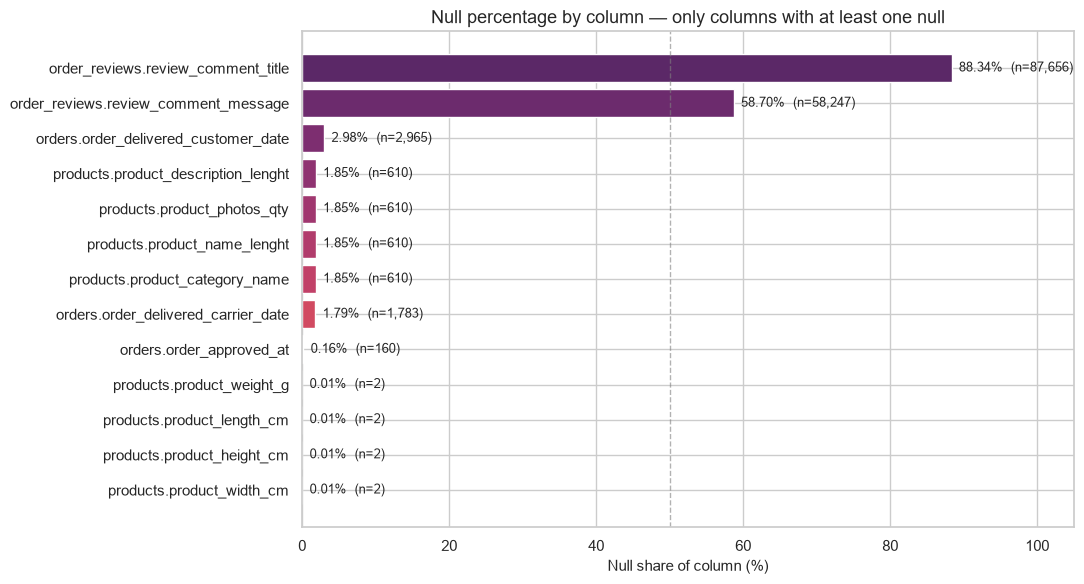

In [5]:
plot_df = missing.sort_values("null_pct", ascending=True).copy()
plot_df["label"] = plot_df["table"] + "." + plot_df["column"]

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(plot_df["label"], plot_df["null_pct"], color=sns.color_palette("flare", len(plot_df)))
for bar, (_, row) in zip(bars, plot_df.iterrows(), strict=False):
    ax.text(
        bar.get_width() + 1.0,
        bar.get_y() + bar.get_height() / 2,
        f"{row['null_pct']:.2f}%  (n={row['n_null']:,})",
        va="center",
        fontsize=9,
    )
ax.set_xlim(0, 105)
ax.set_xlabel("Null share of column (%)")
ax.set_title("Null percentage by column — only columns with at least one null")
ax.axvline(50, color="grey", linestyle="--", linewidth=1, alpha=0.6)
plt.tight_layout()
plt.show()

### 3.1 Business meaning of the important nulls

**`orders.order_delivered_customer_date` — 2,965 nulls (2.98%)**
This is the single most consequential null in the dataset. It means *the order was never
recorded as delivered to the customer*. Breakdown: 2,957 orders are in a non-`delivered`
status (shipped, canceled, unavailable, invoiced, processing, created, approved) and 8 orders
are marked `delivered` but carry no delivery timestamp. **These rows cannot be labelled for
the delivery-delay model** — there is no actual delivery date to compare against the estimate.
They are not "missing data to impute"; they are out of scope for supervised learning.

**`orders.order_delivered_carrier_date` — 1,783 nulls (1.79%)**
The order never reached the carrier handover step. 609 `unavailable`, 550 `canceled`,
314 `invoiced`, 301 `processing`, 5 `created`, 2 `approved`, and 2 `delivered` orders have no
handover timestamp. Business meaning: the seller never shipped. This field is post-purchase
and is **forbidden as a model feature**; it matters only for logistics diagnostics.

**`orders.order_approved_at` — 160 nulls (0.16%)**
Payment was never approved. 141 of the 160 are `canceled` orders (payment failed or was
refused), 5 are `created` (never paid), and 14 are `delivered` — the last group is a genuine
data-quality anomaly (an order delivered without a recorded approval).

**`products.product_category_name` — 610 nulls (1.85%)**
The product exists and was sold but has no catalogue category. All 610 rows are null across
the *entire* product metadata block (`product_name_lenght`, `product_description_lenght`,
`product_photos_qty` are null on exactly the same 610 rows), which indicates these products
were never properly registered in the catalogue. Business meaning: category-level revenue and
delay analysis will under-count unless these are bucketed as `unknown`.

**`products.product_weight_g` / `product_length_cm` / `product_height_cm` / `product_width_cm` — 2 nulls each**
Only two products lack physical dimensions. Negligible (0.006%); median imputation is safe.

**`order_reviews.review_comment_message` — 58,247 nulls (58.70%) and `review_comment_title` — 87,656 nulls (88.34%)**
The customer answered the survey (a score exists) but wrote no free text. 56,518 reviews have
neither a title nor a message. Business meaning: **the score is the reliable signal; text is a
minority sample and is heavily biased toward extreme experiences.** Any NLP work must be
scoped to the 40,977 reviews that actually contain a message, and must not be treated as
representative of all orders.

**Tables with zero nulls:** `customers`, `sellers`, `order_items`, `order_payments`,
`geolocation`, `category_translation`. Their completeness is structural — every row is a
required attribute of an existing entity.

## 4. Keys and grain

**Question:** what does one row represent in each table, and is the candidate primary key
actually unique?

Grain is verified with `duplicated(subset=[...])`, not assumed. A table whose candidate key
has duplicates cannot be joined safely without aggregation first.

In [6]:
grain_checks = [
    ("orders", ["order_id"], "1 row per order"),
    ("order_items", ["order_id", "order_item_id"], "1 row per order line item"),
    ("order_payments", ["order_id", "payment_sequential"], "1 row per payment line"),
    ("order_reviews", ["review_id"], "1 row per review — candidate key"),
    ("order_reviews", ["order_id"], "1 row per order — candidate key"),
    ("customers", ["customer_id"], "1 row per order-scoped customer"),
    ("customers", ["customer_unique_id"], "1 row per person — candidate key"),
    ("sellers", ["seller_id"], "1 row per seller"),
    ("products", ["product_id"], "1 row per product"),
    ("geolocation", ["geolocation_zip_code_prefix"], "many rows per ZIP prefix — candidate key"),
    ("category_translation", ["product_category_name"], "1 row per category"),
]

rows = []
for name, keys, grain in grain_checks:
    df = tables[name]
    dup = int(df.duplicated(subset=keys).sum())
    rows.append(
        {
            "table": name,
            "candidate_key": " + ".join(keys),
            "rows": len(df),
            "distinct_keys": int(df.drop_duplicates(subset=keys).shape[0]),
            "duplicate_key_rows": dup,
            "unique": dup == 0,
            "grain": grain,
        }
    )

grain_table = pd.DataFrame(rows)
display(grain_table)

,table,candidate_key,rows,distinct_keys,duplicate_key_rows,unique,grain
0,orders,order_id,99441,99441,0,True,1 row per order
1,order_items,order_id + order_item_id,112650,112650,0,True,1 row per order line item
2,order_payments,order_id + payment_sequential,103886,103886,0,True,1 row per payment line
3,order_reviews,review_id,99224,98410,814,False,1 row per review — candidate key
4,order_reviews,order_id,99224,98673,551,False,1 row per order — candidate key
5,customers,customer_id,99441,99441,0,True,1 row per order-scoped customer
6,customers,customer_unique_id,99441,96096,3345,False,1 row per person — candidate key
7,sellers,seller_id,3095,3095,0,True,1 row per seller
8,products,product_id,32951,32951,0,True,1 row per product
9,geolocation,geolocation_zip_code_prefix,1000163,19015,981148,False,many rows per ZIP prefix — candidate key


### 4.1 `orders.order_id` — confirmed primary key

`order_id` is unique across all 99,441 rows: zero duplicates. `customer_id` is *also* unique
in `orders` (1:1), which is the first hint that `customer_id` is order-scoped rather than
person-scoped — confirmed in §4.4.

In [7]:
orders = tables["orders"]
print(f"orders rows                     : {len(orders):,}")
print(f"distinct order_id               : {orders['order_id'].nunique():,}")
print(f"duplicated order_id rows        : {int(orders['order_id'].duplicated().sum())}")
print(f"distinct customer_id in orders  : {orders['customer_id'].nunique():,}")
print(f"-> order_id is a valid PK       : {orders['order_id'].is_unique}")
print(f"-> customer_id is 1:1 with order: {orders['customer_id'].is_unique}")

orders rows                     : 99,441
distinct order_id               : 99,441
duplicated order_id rows        : 0
distinct customer_id in orders  : 99,441
-> order_id is a valid PK       : True
-> customer_id is 1:1 with order: True


### 4.2 `order_items` — grain is (order_id, order_item_id)

112,650 rows, zero duplicates on the composite key. `order_item_id` is a sequential line
number **within** an order (1..n), not a global item identifier — it restarts at 1 for every
order. 9,803 orders contain more than one line item (max 21), and 1,278 orders are fulfilled
by more than one seller (max 5). This is why `order_items` **must be aggregated to one row per
order before joining to `orders`**.

In [8]:
items = tables["order_items"]
print(f"order_items rows                        : {len(items):,}")
print(f"duplicated (order_id, order_item_id)    : {int(items.duplicated(['order_id', 'order_item_id']).sum())}")
print(f"distinct orders in order_items          : {items['order_id'].nunique():,}")
print(f"order_item_id range                     : {items['order_item_id'].min()} .. {items['order_item_id'].max()}")

per_order = items.groupby("order_id").agg(
    n_items=("order_item_id", "size"),
    n_sellers=("seller_id", "nunique"),
    n_products=("product_id", "nunique"),
)
print()
print(f"orders with >1 line item                : {int((per_order['n_items'] > 1).sum()):,}")
print(f"max line items in one order             : {int(per_order['n_items'].max())}")
print(f"orders with >1 seller                   : {int((per_order['n_sellers'] > 1).sum()):,}")
print(f"max sellers in one order                : {int(per_order['n_sellers'].max())}")
print(f"mean line items per order               : {per_order['n_items'].mean():.3f}")
print()
print("line items per order (distribution):")
print(per_order["n_items"].value_counts().sort_index().head(8).to_string())

order_items rows                        : 112,650
duplicated (order_id, order_item_id)    : 0
distinct orders in order_items          : 98,666
order_item_id range                     : 1 .. 21

orders with >1 line item                : 9,803
max line items in one order             : 21
orders with >1 seller                   : 1,278
max sellers in one order                : 5
mean line items per order               : 1.142

line items per order (distribution):
n_items
1    88863
2     7516
3     1322
4      505
5      204
6      198
7       22
8        8


### 4.3 `order_payments` — grain is (order_id, payment_sequential)

103,886 rows, zero duplicates on the composite key. `payment_sequential` numbers the payment
lines of a single order (a customer can split payment across a credit card, a voucher and a
boleto). 2,961 orders have more than one payment line (max 29). Same rule as `order_items`:
aggregate before joining.

In [9]:
payments = tables["order_payments"]
print(f"order_payments rows                     : {len(payments):,}")
print(f"duplicated (order_id, payment_sequential): {int(payments.duplicated(['order_id', 'payment_sequential']).sum())}")
print(f"distinct orders in payments             : {payments['order_id'].nunique():,}")
print(f"payment_sequential range                : {payments['payment_sequential'].min()} .. {payments['payment_sequential'].max()}")

pay_per_order = payments.groupby("order_id").size()
print()
print(f"orders with >1 payment line             : {int((pay_per_order > 1).sum()):,}")
print(f"max payment lines in one order          : {int(pay_per_order.max())}")
print()
print("payment_type distribution:")
print(payments["payment_type"].value_counts().to_string())
print()
print(f"payment_installments range              : {payments['payment_installments'].min()} .. {payments['payment_installments'].max()}")

order_payments rows                     : 103,886
duplicated (order_id, payment_sequential): 0
distinct orders in payments             : 99,440
payment_sequential range                : 1 .. 29



orders with >1 payment line             : 2,961
max payment lines in one order          : 29

payment_type distribution:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3

payment_installments range              : 0 .. 24


### 4.4 `order_reviews` — neither `review_id` nor `order_id` is unique

This is the most important grain trap in the dataset. 99,224 review rows cover only 98,673
distinct orders, and only 98,410 distinct `review_id` values.

- **547 orders have more than one review** (max 3 per order).
- **814 rows share a `review_id` with another row** — the same review identifier is reused
  across different orders in the source export.

Consequence: joining `reviews` to `orders` without deduplication **multiplies rows**. Phase 3
must reduce reviews to exactly one row per order (e.g. keep the latest `review_answer_timestamp`,
or the lowest score) before the join.

In [10]:
reviews = tables["order_reviews"]
print(f"review rows                     : {len(reviews):,}")
print(f"distinct review_id              : {reviews['review_id'].nunique():,}")
print(f"distinct order_id               : {reviews['order_id'].nunique():,}")
print(f"review_id is unique             : {reviews['review_id'].is_unique}")
print(f"order_id is unique              : {reviews['order_id'].is_unique}")
print(f"duplicated review_id rows       : {int(reviews['review_id'].duplicated().sum()):,}")
print(f"duplicated order_id rows        : {int(reviews['order_id'].duplicated().sum()):,}")

reviews_per_order = reviews["order_id"].value_counts()
print()
print(f"orders with >1 review           : {int((reviews_per_order > 1).sum()):,}")
print(f"max reviews on a single order   : {int(reviews_per_order.max())}")
print()
print("reviews per order (distribution):")
print(reviews_per_order.value_counts().sort_index().to_string())

reused_ids = reviews.groupby("review_id")["order_id"].nunique()
print()
print(f"review_id values spanning >1 order: {int((reused_ids > 1).sum()):,}")
print(f"rows affected by reused review_id : {int(reviews['review_id'].isin(reused_ids[reused_ids > 1].index).sum()):,}")

review rows                     : 99,224
distinct review_id              : 98,410
distinct order_id               : 98,673
review_id is unique             : False


order_id is unique              : False
duplicated review_id rows       : 814
duplicated order_id rows        : 551

orders with >1 review           : 547
max reviews on a single order   : 3

reviews per order (distribution):
count
1    98126
2      543
3        4



review_id values spanning >1 order: 789


rows affected by reused review_id : 1,603


### 4.5 `geolocation` — many rows per ZIP prefix, no primary key

1,000,163 rows map to only 19,015 distinct ZIP prefixes: a mean of 52.6 rows per prefix,
median 29, maximum 1,146. Each row is one observed coordinate sample for that prefix, so the
table has **no unique key** and cannot be joined directly to `customers` or `sellers` without
aggregation (one representative lat/lng per prefix).

In [11]:
geo = tables["geolocation"]
rows_per_zip = geo["geolocation_zip_code_prefix"].value_counts()

print(f"geolocation rows                : {len(geo):,}")
print(f"distinct ZIP prefixes           : {geo['geolocation_zip_code_prefix'].nunique():,}")
print(f"fully duplicated rows           : {int(geo.duplicated().sum()):,}")
print(f"distinct (zip, lat, lng) combos : {geo.drop_duplicates(['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng']).shape[0]:,}")
print()
print("rows per ZIP prefix:")
print(rows_per_zip.describe().to_string())
print()
print(f"ZIP prefixes with a single row  : {int((rows_per_zip == 1).sum()):,}")
print(f"ZIP prefix with the most rows   : {rows_per_zip.idxmax()} ({rows_per_zip.max():,} rows)")

geolocation rows                : 1,000,163
distinct ZIP prefixes           : 19,015


fully duplicated rows           : 261,831


distinct (zip, lat, lng) combos : 720,154

rows per ZIP prefix:
count   19,015.000
mean        52.599
std         72.058
min          1.000
25%         10.000
50%         29.000
75%         66.500
max      1,146.000

ZIP prefixes with a single row  : 1,043
ZIP prefix with the most rows   : 24220 (1,146 rows)


### 4.6 `customers.customer_id` vs `customer_unique_id`

These two columns answer different questions and confusing them is a classic Olist mistake.

| Column | Scope | Unique values | Use for |
|--------|-------|---------------|---------|
| `customer_id` | **One per order** — a surrogate key generated for each order | 99,441 (= row count) | Joining `orders` → `customers` |
| `customer_unique_id` | **One per real person** — stable across that person's orders | 96,096 | Repeat-purchase rate, CLV, cohort analysis |

Because `customer_id` is order-scoped, counting distinct `customer_id` gives the number of
*orders*, not customers. Repeat-purchase analysis **must** use `customer_unique_id`.

In [12]:
customers = tables["customers"]
print(f"customers rows                  : {len(customers):,}")
print(f"distinct customer_id            : {customers['customer_id'].nunique():,}")
print(f"distinct customer_unique_id     : {customers['customer_unique_id'].nunique():,}")
print(f"customer_id is unique           : {customers['customer_id'].is_unique}")

orders_per_person = customers["customer_unique_id"].value_counts()
repeat = int((orders_per_person > 1).sum())
print()
print(f"people with >1 order (repeat)   : {repeat:,}")
print(f"repeat-purchase rate            : {repeat / customers['customer_unique_id'].nunique() * 100:.2f}% of people")
print(f"max orders by one person        : {int(orders_per_person.max())}")
print()
print("orders per person (distribution, top 6):")
print(orders_per_person.value_counts().sort_index().head(6).to_string())

customers rows                  : 99,441
distinct customer_id            : 99,441
distinct customer_unique_id     : 96,096
customer_id is unique           : True

people with >1 order (repeat)   : 2,997
repeat-purchase rate            : 3.12% of people
max orders by one person        : 17

orders per person (distribution, top 6):
count
1    93099
2     2745
3      203
4       30
5        8
6        6


## 5. Relationships and foreign-key integrity

**Question:** does every foreign key resolve to an existing parent row, and what is the
cardinality of each relationship?

Orphan count = number of child rows whose FK value is absent from the parent's key set.
A non-zero orphan count means the join will silently drop rows.

In [13]:
def orphan_count(child: pd.DataFrame, child_col: str, parent: pd.DataFrame, parent_col: str) -> int:
    parent_keys = set(parent[parent_col].dropna().unique())
    return int((~child[child_col].isin(parent_keys)).sum())


fk_checks = [
    ("orders.customer_id", orders, "customer_id", customers, "customer_id", "many-to-one"),
    ("order_items.order_id", items, "order_id", orders, "order_id", "many-to-one"),
    ("order_items.product_id", items, "product_id", tables["products"], "product_id", "many-to-one"),
    ("order_items.seller_id", items, "seller_id", tables["sellers"], "seller_id", "many-to-one"),
    ("order_payments.order_id", payments, "order_id", orders, "order_id", "many-to-one"),
    ("order_reviews.order_id", reviews, "order_id", orders, "order_id", "many-to-one"),
    ("customers.zip -> geolocation", customers, "customer_zip_code_prefix", geo, "geolocation_zip_code_prefix", "many-to-many"),
    ("sellers.zip -> geolocation", tables["sellers"], "seller_zip_code_prefix", geo, "geolocation_zip_code_prefix", "many-to-many"),
    ("products.category -> translation", tables["products"], "product_category_name", tables["category_translation"], "product_category_name", "many-to-one"),
]

fk_rows = []
for label, child, ccol, parent, pcol, card in fk_checks:
    n_orphans = orphan_count(child, ccol, parent, pcol)
    fk_rows.append(
        {
            "relationship": label,
            "cardinality": card,
            "child_rows": len(child),
            "orphan_rows": n_orphans,
            "orphan_pct": round(n_orphans / len(child) * 100, 3),
            "resolves": n_orphans == 0,
        }
    )

fk_table = pd.DataFrame(fk_rows)
display(fk_table)
print(f"Relationships with zero orphans: {int(fk_table['resolves'].sum())} of {len(fk_table)}")

,relationship,cardinality,child_rows,orphan_rows,orphan_pct,resolves
0,orders.customer_id,many-to-one,99441,0,0.000,True
1,order_items.order_id,many-to-one,112650,0,0.000,True
2,order_items.product_id,many-to-one,112650,0,0.000,True
3,order_items.seller_id,many-to-one,112650,0,0.000,True
4,order_payments.order_id,many-to-one,103886,0,0.000,True
5,order_reviews.order_id,many-to-one,99224,0,0.000,True
6,customers.zip -> geolocation,many-to-many,99441,278,0.280,False
7,sellers.zip -> geolocation,many-to-many,3095,7,0.226,False
8,products.category -> translation,many-to-one,32951,623,1.891,False


Relationships with zero orphans: 6 of 9


### 5.1 Coverage — orders missing from the one-to-many tables

FK integrity is clean, but that does not mean every order has children. These are *coverage*
gaps, not referential errors, and they determine whether Phase 3 uses `LEFT JOIN` or
`INNER JOIN`.

In [14]:
coverage = pd.DataFrame(
    [
        {
            "child_table": "order_items",
            "orders_without_child": int((~orders["order_id"].isin(set(items["order_id"]))).sum()),
        },
        {
            "child_table": "order_payments",
            "orders_without_child": int((~orders["order_id"].isin(set(payments["order_id"]))).sum()),
        },
        {
            "child_table": "order_reviews",
            "orders_without_child": int((~orders["order_id"].isin(set(reviews["order_id"]))).sum()),
        },
    ]
)
coverage["pct_of_orders"] = (coverage["orders_without_child"] / len(orders) * 100).round(3)
display(coverage)

print("Status of orders with no line items:")
print(
    orders.loc[~orders["order_id"].isin(set(items["order_id"])), "order_status"]
    .value_counts()
    .to_string()
)
print()
print("The single order with no payment row:")
print(
    orders.loc[~orders["order_id"].isin(set(payments["order_id"])), ["order_id", "order_status"]]
    .to_string(index=False)
)

,child_table,orders_without_child,pct_of_orders
0,order_items,775,0.779
1,order_payments,1,0.001
2,order_reviews,768,0.772


Status of orders with no line items:


order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1

The single order with no payment row:


                        order_id order_status
bfbd0f9bdef84302105ad712db648a6c    delivered


### 5.2 Entity-relationship diagram

```mermaid
erDiagram
    CUSTOMERS ||--o{ ORDERS : "customer_id (1:1 in practice)"
    ORDERS ||--o{ ORDER_ITEMS : "order_id"
    ORDERS ||--o{ ORDER_PAYMENTS : "order_id"
    ORDERS ||--o{ ORDER_REVIEWS : "order_id"
    PRODUCTS ||--o{ ORDER_ITEMS : "product_id"
    SELLERS ||--o{ ORDER_ITEMS : "seller_id"
    PRODUCT_CATEGORY_NAME_TRANSLATION ||--o{ PRODUCTS : "product_category_name"
    GEOLOCATION ||--o{ CUSTOMERS : "zip_code_prefix (many geo rows per prefix)"
    GEOLOCATION ||--o{ SELLERS : "zip_code_prefix (many geo rows per prefix)"

    ORDERS {
        string order_id PK
        string customer_id FK
        string order_status
        datetime order_purchase_timestamp
        datetime order_approved_at
        datetime order_delivered_carrier_date
        datetime order_delivered_customer_date
        datetime order_estimated_delivery_date
    }
    ORDER_ITEMS {
        string order_id PK
        int order_item_id PK
        string product_id FK
        string seller_id FK
        datetime shipping_limit_date
        float price
        float freight_value
    }
    ORDER_PAYMENTS {
        string order_id PK
        int payment_sequential PK
        string payment_type
        int payment_installments
        float payment_value
    }
    ORDER_REVIEWS {
        string review_id
        string order_id FK
        int review_score
        string review_comment_title
        string review_comment_message
        datetime review_creation_date
        datetime review_answer_timestamp
    }
    CUSTOMERS {
        string customer_id PK
        string customer_unique_id
        int customer_zip_code_prefix FK
        string customer_city
        string customer_state
    }
    SELLERS {
        string seller_id PK
        int seller_zip_code_prefix FK
        string seller_city
        string seller_state
    }
    PRODUCTS {
        string product_id PK
        string product_category_name FK
        int product_name_lenght
        int product_description_lenght
        int product_photos_qty
        int product_weight_g
        int product_length_cm
        int product_height_cm
        int product_width_cm
    }
    GEOLOCATION {
        int geolocation_zip_code_prefix
        float geolocation_lat
        float geolocation_lng
        string geolocation_city
        string geolocation_state
    }
    PRODUCT_CATEGORY_NAME_TRANSLATION {
        string product_category_name PK
        string product_category_name_english
    }
```

**Cardinality notes.**

- `orders` → `customers` is declared many-to-one but is **1:1 in practice** because
  `customer_id` is order-scoped. The person-level relationship is
  `orders` → `customers.customer_unique_id`, which is many-to-one.
- `orders` → `order_items`, `order_payments`, `order_reviews` are all **one-to-many** and must
  be aggregated to one row per order before joining to `orders`.
- `geolocation` is a **lookup with many rows per key** — effectively many-to-many. It must be
  collapsed to one representative coordinate per ZIP prefix.
- `order_reviews` has no valid single-column key: `review_id` is reused (814 duplicate rows)
  and `order_id` repeats (547 orders with multiple reviews).

## 6. Data dictionary

Every column of every table, with dtype, description, business meaning, nullability and
notes. Descriptions are based on the observed data, not on the Kaggle documentation alone.

### 6.1 `orders` — 99,441 rows x 8 columns

| Column | dtype | Description | Business meaning | Nullable? | Notes |
|--------|-------|-------------|------------------|-----------|-------|
| `order_id` | str | 32-char hex order identifier | Primary key; one row per order | No | Unique across all 99,441 rows |
| `customer_id` | str | Order-scoped customer key | FK to `customers.customer_id`; identifies the customer *record* attached to this order, not the person | No | 1:1 with `order_id` — a new value per order |
| `order_status` | str | Lifecycle status | Where the order sits in fulfilment | No | 8 values; `delivered` = 96,478 (97.02%) |
| `order_purchase_timestamp` | datetime | Order placement timestamp | **Prediction timestamp** for the ML model — the instant at which all features must be knowable | No | Range 2016-09-04 → 2018-10-17 |
| `order_approved_at` | datetime | Payment approval timestamp | Payment cleared; the order entered fulfilment | Yes (160) | 141 of 160 nulls are `canceled` |
| `order_delivered_carrier_date` | datetime | Handover to the logistics provider | Seller shipped; start of carrier transit | Yes (1,783) | Post-purchase — forbidden as a feature |
| `order_delivered_customer_date` | datetime | Actual delivery to the customer | **Target source** — compared with the estimate to derive `is_late` | Yes (2,965) | Null for 2,957 undelivered + 8 delivered-without-date |
| `order_estimated_delivery_date` | datetime | Estimated delivery date shown at purchase | Known at purchase; usable only as derived lead time (estimate − purchase) | No | Date-only, always 00:00:00 |

### 6.2 `order_items` — 112,650 rows x 7 columns

| Column | dtype | Description | Business meaning | Nullable? | Notes |
|--------|-------|-------------|------------------|-----------|-------|
| `order_id` | str | FK to `orders` | Order the line belongs to | No | 775 orders have no line items |
| `order_item_id` | int | Sequential line number within the order (1..n) | With `order_id` forms the composite PK | No | Restarts at 1 per order; max 21 |
| `product_id` | str | FK to `products` | Product sold on this line | No | 0 orphans |
| `seller_id` | str | FK to `sellers` | Seller fulfilling this line | No | 0 orphans; 1,278 orders have >1 seller |
| `shipping_limit_date` | datetime | Seller's deadline to hand the item to the carrier | Operational SLA field | No | Post-purchase — forbidden as a feature |
| `price` | float | Item price in BRL | Revenue per line | No | Min 0.85, max 6,735; no zero or negative values |
| `freight_value` | float | Freight charged for this line in BRL | Shipping cost attributable to the item | No | 383 lines have 0 freight; max 409.68 |

### 6.3 `order_payments` — 103,886 rows x 5 columns

| Column | dtype | Description | Business meaning | Nullable? | Notes |
|--------|-------|-------------|------------------|-----------|-------|
| `order_id` | str | FK to `orders` | Order being paid | No | 1 order has no payment row |
| `payment_sequential` | int | Payment line number within the order | With `order_id` forms the composite PK | No | Max 29 lines |
| `payment_type` | str | Payment method | How the customer paid | No | credit_card 76,795; boleto 19,784; voucher 5,775; debit_card 1,529; not_defined 3 |
| `payment_installments` | int | Number of instalments | Financing behaviour | No | 1..24 |
| `payment_value` | float | Amount paid on this line in BRL | Summed per order = order revenue | No | 9 rows are 0.0 (voucher / not_defined) |

### 6.4 `order_reviews` — 99,224 rows x 7 columns

| Column | dtype | Description | Business meaning | Nullable? | Notes |
|--------|-------|-------------|------------------|-----------|-------|
| `review_id` | str | Review identifier | Candidate key | No | **Not unique** — 98,410 distinct; 814 duplicate rows |
| `order_id` | str | FK to `orders` | Order being reviewed | No | 98,673 distinct; 547 orders have >1 review |
| `review_score` | int | Satisfaction score 1–5 | Primary customer-experience KPI | No | Mean 4.09; 11,424 ones, 57,328 fives |
| `review_comment_title` | str | Free-text title | Optional survey field | Yes (87,656 = 88.34%) | — |
| `review_comment_message` | str | Free-text comment | Optional survey field | Yes (58,247 = 58.70%) | 56,518 reviews have neither title nor message |
| `review_creation_date` | datetime | Date the satisfaction survey was sent | Post-purchase | No | — |
| `review_answer_timestamp` | datetime | Timestamp the customer answered | Post-purchase | No | Use to pick the latest review per order |

### 6.5 `customers` — 99,441 rows x 5 columns

| Column | dtype | Description | Business meaning | Nullable? | Notes |
|--------|-------|-------------|------------------|-----------|-------|
| `customer_id` | str | Order-scoped customer key | PK; joins to `orders.customer_id` | No | 99,441 unique = row count |
| `customer_unique_id` | str | Person-level customer key | The real customer identity — use for repeat purchase and CLV | No | 96,096 unique → 2,997 repeat customers |
| `customer_zip_code_prefix` | int | First 5 digits of the ZIP code | FK to `geolocation` prefix | No | 278 prefixes absent from `geolocation` |
| `customer_city` | str | City name | Geography | No | Not normalised — case and accents vary |
| `customer_state` | str | 2-letter state code | Geography | No | 27 states; SP = 41,746 |

### 6.6 `sellers` — 3,095 rows x 4 columns

| Column | dtype | Description | Business meaning | Nullable? | Notes |
|--------|-------|-------------|------------------|-----------|-------|
| `seller_id` | str | Seller identifier | PK | No | 3,095 unique |
| `seller_zip_code_prefix` | int | First 5 digits of the seller ZIP | FK to `geolocation` prefix | No | 7 prefixes absent from `geolocation` |
| `seller_city` | str | City name | Geography | No | Not normalised |
| `seller_state` | str | 2-letter state code | Geography | No | — |

### 6.7 `products` — 32,951 rows x 9 columns

| Column | dtype | Description | Business meaning | Nullable? | Notes |
|--------|-------|-------------|------------------|-----------|-------|
| `product_id` | str | Product identifier | PK | No | 32,951 unique |
| `product_category_name` | str | Category name in Portuguese | FK to `category_translation` | Yes (610 = 1.85%) | 2 categories absent from the translation table |
| `product_name_lenght` | int | Character count of the product name | Listing-quality proxy | Yes (610) | Column name misspelled in the source |
| `product_description_lenght` | int | Character count of the description | Listing-quality proxy | Yes (610) | Misspelled in the source |
| `product_photos_qty` | int | Number of photos on the listing | Listing-quality proxy | Yes (610) | — |
| `product_weight_g` | int | Weight in grams | Shipping-cost driver | Yes (2) | — |
| `product_length_cm` | int | Length in cm | Volume / shipping driver | Yes (2) | — |
| `product_height_cm` | int | Height in cm | Volume / shipping driver | Yes (2) | — |
| `product_width_cm` | int | Width in cm | Volume / shipping driver | Yes (2) | — |

### 6.8 `geolocation` — 1,000,163 rows x 5 columns

| Column | dtype | Description | Business meaning | Nullable? | Notes |
|--------|-------|-------------|------------------|-----------|-------|
| `geolocation_zip_code_prefix` | int | First 5 digits of the ZIP code | Join key to `customers` and `sellers` | No | 19,015 distinct; 52.6 rows per prefix on average |
| `geolocation_lat` | float | Latitude | Distance computation | No | Range −36.6 → 45.1; values outside Brazil exist |
| `geolocation_lng` | float | Longitude | Distance computation | No | Range −101.5 → 121.1 |
| `geolocation_city` | str | City name | Geography | No | Inconsistent spelling across rows |
| `geolocation_state` | str | 2-letter state code | Geography | No | 8 prefixes map to more than one state |

### 6.9 `product_category_name_translation` — 71 rows x 2 columns

| Column | dtype | Description | Business meaning | Nullable? | Notes |
|--------|-------|-------------|------------------|-----------|-------|
| `product_category_name` | str | Category name in Portuguese | PK; joins to `products` | No | 71 rows vs 73 distinct categories in `products` |
| `product_category_name_english` | str | English translation | Reporting label for dashboards | No | — |

## 7. Data-quality issues

**Question:** which specific defects will constrain cleaning, ETL and modelling, and how large
is each one?

Every number below is produced by the code immediately preceding it.

### 7.1 `order_status` distribution

**Question:** how many orders are not `delivered`, and does that matter for the ML label?

In [15]:
status_counts = orders["order_status"].value_counts().to_frame("orders")
status_counts["pct"] = (status_counts["orders"] / len(orders) * 100).round(3)
status_counts["cumulative_pct"] = status_counts["pct"].cumsum().round(3)
display(status_counts)

non_delivered = int((orders["order_status"] != "delivered").sum())
print(f"Non-delivered orders: {non_delivered:,} of {len(orders):,} ({non_delivered / len(orders) * 100:.2f}%)")
print()
print("Implication: only `delivered` orders can carry a delivery-delay label.")

,orders,pct,cumulative_pct
order_status,,,
delivered,96478,97.020,97.020
shipped,1107,1.113,98.133
canceled,625,0.629,98.762
unavailable,609,0.612,99.374
invoiced,314,0.316,99.690
processing,301,0.303,99.993
created,5,0.005,99.998
approved,2,0.002,100.000


Non-delivered orders: 2,963 of 99,441 (2.98%)

Implication: only `delivered` orders can carry a delivery-delay label.


### 7.2 Status vs. delivery-date presence

**Question:** are there orders whose status and delivery timestamp contradict each other?

Two failure modes matter: `delivered` with no delivery date (unlabelable) and a non-`delivered`
status that nevertheless carries a delivery date (label would be wrong).

In [16]:
crosstab = pd.crosstab(
    orders["order_status"],
    orders["order_delivered_customer_date"].notna().rename("has_delivery_date"),
    margins=True,
)
display(crosstab)

delivered_no_date = orders[(orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()]
not_delivered_with_date = orders[(orders["order_status"] != "delivered") & orders["order_delivered_customer_date"].notna()]

print(f"status == 'delivered' but no delivery date : {len(delivered_no_date):,}")
print(f"status != 'delivered' but has delivery date: {len(not_delivered_with_date):,}")
print()
print("Non-delivered statuses carrying a delivery date:")
print(not_delivered_with_date["order_status"].value_counts().to_string())
print()
print("The 8 'delivered' orders with no delivery timestamp:")
print(delivered_no_date[["order_id", "order_purchase_timestamp", "order_delivered_customer_date"]].to_string(index=False))

has_delivery_date,False,True,All
order_status,,,
approved,2,0,2
canceled,619,6,625
created,5,0,5
delivered,8,96470,96478
invoiced,314,0,314
processing,301,0,301
shipped,1107,0,1107
unavailable,609,0,609
All,2965,96476,99441


status == 'delivered' but no delivery date : 8
status != 'delivered' but has delivery date: 6

Non-delivered statuses carrying a delivery date:
order_status
canceled    6

The 8 'delivered' orders with no delivery timestamp:
                        order_id order_purchase_timestamp order_delivered_customer_date
2d1e2d5bf4dc7227b3bfebb81328c15f      2017-11-28 17:44:07                           NaN
f5dd62b788049ad9fc0526e3ad11a097      2018-06-20 06:58:43                           NaN
2ebdfc4f15f23b91474edf87475f108e      2018-07-01 17:05:11                           NaN
e69f75a717d64fc5ecdfae42b2e8e086      2018-07-01 22:05:55                           NaN
0d3268bad9b086af767785e3f0fc0133      2018-07-01 21:14:02                           NaN
2d858f451373b04fb5c984a1cc2defaf      2017-05-25 23:22:43                           NaN
ab7c89dc1bf4a1ead9d6ec1ec8968a84      2018-06-08 12:09:39                           NaN
20edc82cf5400ce95e1afacc25798b31      2018-06-27 16:09:12              

### 7.3 Timestamp ordering violations

**Question:** does the order lifecycle ever run backwards?

Expected sequence: `purchase` → `approved` → `carrier handover` → `delivered`.

In [17]:
orders_dt = orders.copy()
TS_COLS = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in TS_COLS:
    orders_dt[col] = pd.to_datetime(orders_dt[col])

violations = pd.DataFrame(
    [
        {
            "rule": "approved_at < purchase_timestamp",
            "violations": int((orders_dt["order_approved_at"] < orders_dt["order_purchase_timestamp"]).sum()),
        },
        {
            "rule": "carrier_date < purchase_timestamp",
            "violations": int((orders_dt["order_delivered_carrier_date"] < orders_dt["order_purchase_timestamp"]).sum()),
        },
        {
            "rule": "delivered_customer_date < carrier_date",
            "violations": int((orders_dt["order_delivered_customer_date"] < orders_dt["order_delivered_carrier_date"]).sum()),
        },
        {
            "rule": "delivered_customer_date < purchase_timestamp",
            "violations": int((orders_dt["order_delivered_customer_date"] < orders_dt["order_purchase_timestamp"]).sum()),
        },
        {
            "rule": "estimated_delivery_date < purchase_timestamp",
            "violations": int((orders_dt["order_estimated_delivery_date"] < orders_dt["order_purchase_timestamp"]).sum()),
        },
    ]
)
violations["pct_of_orders"] = (violations["violations"] / len(orders_dt) * 100).round(4)
display(violations)

print("Status of orders where carrier handover precedes purchase:")
print(
    orders_dt.loc[
        orders_dt["order_delivered_carrier_date"] < orders_dt["order_purchase_timestamp"], "order_status"
    ]
    .value_counts()
    .to_string()
)
print()
print("Status of orders delivered before carrier handover:")
print(
    orders_dt.loc[
        orders_dt["order_delivered_customer_date"] < orders_dt["order_delivered_carrier_date"], "order_status"
    ]
    .value_counts()
    .to_string()
)

,rule,violations,pct_of_orders
0,approved_at < purchase_timestamp,0,0.000
1,carrier_date < purchase_timestamp,166,0.167
2,delivered_customer_date < carrier_date,23,0.023
3,delivered_customer_date < purchase_timestamp,0,0.000
4,estimated_delivery_date < purchase_timestamp,0,0.000


Status of orders where carrier handover precedes purchase:
order_status
delivered    165
shipped        1

Status of orders delivered before carrier handover:
order_status
delivered    23


**Interpretation.** 166 orders (0.17%) show a carrier handover *before* the purchase timestamp
and 23 orders (0.02%) show delivery *before* handover. Both are physically impossible and
point to timestamp-entry errors in the source system. The purchase → approved and
purchase → delivered orderings are clean (zero violations), so the purchase timestamp itself
is trustworthy — which is what matters, since it is the ML prediction timestamp. These
violations affect only post-purchase duration diagnostics, not the label.

### 7.4 Date range and density of `order_purchase_timestamp`

**Question:** is the observation window dense enough at both ends for chronological splitting?

In [18]:
print(f"Earliest purchase: {orders_dt['order_purchase_timestamp'].min()}")
print(f"Latest purchase  : {orders_dt['order_purchase_timestamp'].max()}")
print(f"Span             : {(orders_dt['order_purchase_timestamp'].max() - orders_dt['order_purchase_timestamp'].min()).days:,} days")
print()

monthly = orders_dt["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index()
monthly_df = monthly.to_frame("orders")
monthly_df["pct_of_total"] = (monthly_df["orders"] / len(orders_dt) * 100).round(3)
display(monthly_df)

print(f"Orders in 2016 (sparse tail)          : {int((orders_dt['order_purchase_timestamp'].dt.year == 2016).sum()):,}")
print(f"Orders before 2017-01-01              : {int((orders_dt['order_purchase_timestamp'] < '2017-01-01').sum()):,}")
print(f"Orders in 2018-09 and 2018-10 (truncated tail): {int((orders_dt['order_purchase_timestamp'] >= '2018-09-01').sum()):,}")
print(f"Orders after 2018-08-31               : {int((orders_dt['order_purchase_timestamp'] > '2018-08-31').sum()):,}")

Earliest purchase: 2016-09-04 21:15:19
Latest purchase  : 2018-10-17 17:30:18
Span             : 772 days



,orders,pct_of_total
order_purchase_timestamp,,
2016-09,4,0.004
2016-10,324,0.326
2016-12,1,0.001
2017-01,800,0.804
2017-02,1780,1.790
2017-03,2682,2.697
2017-04,2404,2.418
2017-05,3700,3.721
2017-06,3245,3.263


Orders in 2016 (sparse tail)          : 329
Orders before 2017-01-01              : 329
Orders in 2018-09 and 2018-10 (truncated tail): 20
Orders after 2018-08-31               : 21


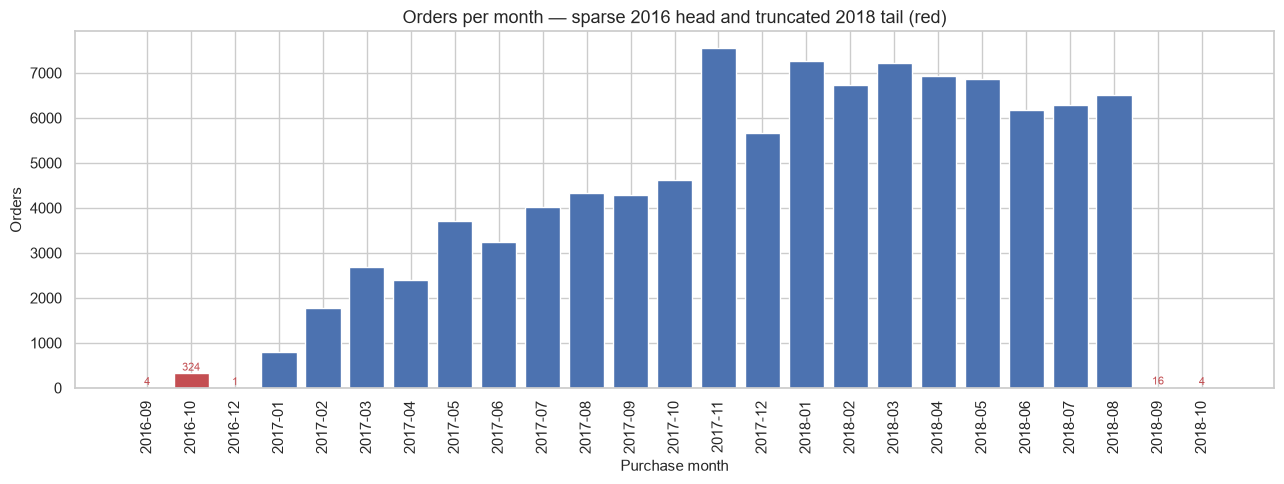

In [19]:
fig, ax = plt.subplots(figsize=(13, 5))
colors = [
    "#c44e52" if (p.year == 2016 or (p.year == 2018 and p.month >= 9)) else "#4c72b0"
    for p in monthly.index
]
ax.bar([str(p) for p in monthly.index], monthly.values, color=colors)
ax.set_title("Orders per month — sparse 2016 head and truncated 2018 tail (red)")
ax.set_ylabel("Orders")
ax.set_xlabel("Purchase month")
ax.tick_params(axis="x", rotation=90)
for i, v in enumerate(monthly.values):
    if v < 500:
        ax.text(i, v + 60, str(v), ha="center", fontsize=8, color="#c44e52")
plt.tight_layout()
plt.show()

**Interpretation.** The window runs 2016-09-04 → 2018-10-17, but it is not uniformly dense:

- **2016 head is sparse:** 329 orders in total (4 in Sep, 324 in Oct, 1 in Dec, none in Nov).
  That is 0.33% of the data — too thin to train on and too thin to compute stable historical
  seller features.
- **2018 tail is truncated:** only 20 orders in Sep–Oct 2018 (16 + 4), versus ~6,300 per month
  earlier in the year. The dataset was cut mid-month, so the last two months are incomplete.

**Consequence for Phase 6:** chronological splits should start at **2017-01** and end at
**2018-08**, otherwise the test set is dominated by a truncated month and the training set
starts with a near-empty period.

### 7.5 `order_estimated_delivery_date` is date-only

**Question:** does the 00:00:00 time component bias the `is_late` label?

In [20]:
est = orders_dt["order_estimated_delivery_date"]
midnight_share = (est.dt.time.astype(str) == "00:00:00").mean()
print(f"Share of estimated dates at exactly 00:00:00: {midnight_share * 100:.2f}%")
print(f"Distinct time components in estimated dates : {est.dt.time.nunique()}")
print()

eligible = orders_dt[
    (orders_dt["order_status"] == "delivered")
    & orders_dt["order_delivered_customer_date"].notna()
    & orders_dt["order_estimated_delivery_date"].notna()
].copy()
eligible["is_late"] = eligible["order_delivered_customer_date"] > eligible["order_estimated_delivery_date"]

same_day = (
    eligible["order_delivered_customer_date"].dt.normalize()
    == eligible["order_estimated_delivery_date"].dt.normalize()
)
late_strict = int(eligible["is_late"].sum())
late_end_of_day = int(
    (eligible["order_delivered_customer_date"] > eligible["order_estimated_delivery_date"] + pd.Timedelta(days=1)).sum()
)

print(f"Eligible orders (delivered + both dates)     : {len(eligible):,}")
print(f"Late under strict comparison (delivered > est): {late_strict:,} ({late_strict / len(eligible) * 100:.2f}%)")
print(f"Delivered on the same calendar day as est    : {int(same_day.sum()):,}")
print(f"Late if estimate is treated as end-of-day    : {late_end_of_day:,} ({late_end_of_day / len(eligible) * 100:.2f}%)")
print(f"Orders reclassified by the end-of-day rule   : {late_strict - late_end_of_day:,}")

Share of estimated dates at exactly 00:00:00: 100.00%
Distinct time components in estimated dates : 1

Eligible orders (delivered + both dates)     : 96,470
Late under strict comparison (delivered > est): 7,826 (8.11%)
Delivered on the same calendar day as est    : 1,292
Late if estimate is treated as end-of-day    : 6,534 (6.77%)
Orders reclassified by the end-of-day rule   : 1,292


**Interpretation.** The estimate carries **no time component at all** — 100% of values are
exactly `00:00:00`. Comparing a real delivery timestamp (which has a time of day) against a
midnight estimate means **any delivery on the estimated day itself counts as late**, even if
it arrived at 09:00.

That affects **1,292 orders** — 16.5% of all "late" orders. If the estimate is instead read as
"end of the estimated day" (the natural business reading of a promised date), the late rate
falls from **8.11% to 6.77%**.

**Decision required in Phase 3/6:** the strict comparison is the project's documented target
(`is_late = delivered > estimated`), so it is kept for consistency with `CONTEXT.md`. The
end-of-day variant must be recorded as a sensitivity check, because a 1,292-order swing is
large relative to the 7,826 positives.

### 7.6 Products with missing category and dimensions

**Question:** how much of the catalogue is unclassifiable or unmeasurable?

In [21]:
products = tables["products"]
translation = tables["category_translation"]

n_null_cat = int(products["product_category_name"].isna().sum())
n_null_dims = int(products[["product_length_cm", "product_height_cm", "product_width_cm"]].isna().any(axis=1).sum())
n_null_weight = int(products["product_weight_g"].isna().sum())

print(f"products rows                          : {len(products):,}")
print(f"null product_category_name             : {n_null_cat:,} ({n_null_cat / len(products) * 100:.2f}%)")
print(f"null weight                            : {n_null_weight:,}")
print(f"null any dimension                     : {n_null_dims:,}")
print(f"distinct categories in products        : {products['product_category_name'].nunique()}")
print(f"rows in translation table              : {len(translation)}")
print()

untranslated = set(products["product_category_name"].dropna()) - set(translation["product_category_name"])
untranslated_rows = int(products["product_category_name"].isin(untranslated).sum())
print(f"Categories present in products but absent from translation: {len(untranslated)}")
print(f"  -> {sorted(untranslated)}")
print(f"Product rows affected by missing translation: {untranslated_rows:,}")
print()

all_null_block = products[
    products[["product_category_name", "product_name_lenght", "product_description_lenght", "product_photos_qty"]]
    .isna()
    .all(axis=1)
]
print(f"Rows where the whole metadata block is null: {len(all_null_block):,}")
print("-> the 610 null categories are products never registered in the catalogue, not random gaps.")

products rows                          : 32,951
null product_category_name             : 610 (1.85%)
null weight                            : 2
null any dimension                     : 2
distinct categories in products        : 73
rows in translation table              : 71

Categories present in products but absent from translation: 2
  -> ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Product rows affected by missing translation: 13

Rows where the whole metadata block is null: 610
-> the 610 null categories are products never registered in the catalogue, not random gaps.


### 7.7 Non-positive prices, freight and payment values

**Question:** are there zero or negative monetary values that would corrupt revenue aggregates?

In [22]:
money = pd.DataFrame(
    [
        {"check": "order_items.price <= 0", "rows": int((items["price"] <= 0).sum())},
        {"check": "order_items.freight_value < 0", "rows": int((items["freight_value"] < 0).sum())},
        {"check": "order_items.freight_value == 0", "rows": int((items["freight_value"] == 0).sum())},
        {"check": "order_payments.payment_value <= 0", "rows": int((payments["payment_value"] <= 0).sum())},
        {"check": "order_payments.payment_installments == 0", "rows": int((payments["payment_installments"] == 0).sum())},
    ]
)
money["pct_of_table"] = [
    round(money.loc[0, "rows"] / len(items) * 100, 4),
    round(money.loc[1, "rows"] / len(items) * 100, 4),
    round(money.loc[2, "rows"] / len(items) * 100, 4),
    round(money.loc[3, "rows"] / len(payments) * 100, 4),
    round(money.loc[4, "rows"] / len(payments) * 100, 4),
]
display(money)

print("order_items.price:")
print(items["price"].describe().to_string())
print()
print("order_items.freight_value:")
print(items["freight_value"].describe().to_string())
print()
print("Rows with payment_value <= 0:")
print(payments.loc[payments["payment_value"] <= 0, ["order_id", "payment_sequential", "payment_type", "payment_value"]].to_string(index=False))

,check,rows,pct_of_table
0,order_items.price <= 0,0,0.000
1,order_items.freight_value < 0,0,0.000
2,order_items.freight_value == 0,383,0.340
3,order_payments.payment_value <= 0,9,0.009
4,order_payments.payment_installments == 0,2,0.002


order_items.price:
count   112,650.000
mean        120.654
std         183.634
min           0.850
25%          39.900
50%          74.990
75%         134.900
max       6,735.000

order_items.freight_value:
count   112,650.000
mean         19.990
std          15.806
min           0.000
25%          13.080
50%          16.260
75%          21.150
max         409.680

Rows with payment_value <= 0:
                        order_id  payment_sequential payment_type  payment_value
8bcbe01d44d147f901cd3192671144db                   4      voucher          0.000
fa65dad1b0e818e3ccc5cb0e39231352                  14      voucher          0.000
6ccb433e00daae1283ccc956189c82ae                   4      voucher          0.000
4637ca194b6387e2d538dc89b124b0ee                   1  not_defined          0.000
00b1cb0320190ca0daa2c88b35206009                   1  not_defined          0.000
45ed6e85398a87c253db47c2d9f48216                   3      voucher          0.000
fa65dad1b0e818e3ccc5cb0e39231352   

**Interpretation.** No item has a zero or negative price (minimum 0.85 BRL), so item-level
revenue is safe. 383 line items (0.34%) carry **zero freight** — legitimate free-shipping
promotions, not errors. 9 payment lines have `payment_value = 0.0`, all of them `voucher` or
`not_defined` lines that sit alongside a real payment line in the same order; they must be
kept (they are part of the payment sequence) but must not be counted as revenue.

### 7.8 Geolocation: conflicting coordinates and missing prefixes

**Question:** can a ZIP prefix be mapped to a single reliable coordinate?

In [23]:
geo_stats = geo.groupby("geolocation_zip_code_prefix").agg(
    rows=("geolocation_lat", "size"),
    distinct_lat=("geolocation_lat", "nunique"),
    distinct_lng=("geolocation_lng", "nunique"),
    distinct_state=("geolocation_state", "nunique"),
)
conflicting_coords = int(((geo_stats["distinct_lat"] > 1) | (geo_stats["distinct_lng"] > 1)).sum())
conflicting_state = int((geo_stats["distinct_state"] > 1).sum())

print(f"ZIP prefixes in geolocation                 : {len(geo_stats):,}")
print(f"Prefixes with >1 distinct lat or lng        : {conflicting_coords:,} ({conflicting_coords / len(geo_stats) * 100:.2f}%)")
print(f"Prefixes mapping to >1 state                : {conflicting_state:,}")
print(f"Prefixes with exactly one coordinate pair   : {int(((geo_stats['distinct_lat'] == 1) & (geo_stats['distinct_lng'] == 1)).sum()):,}")
print()

cust_zip_missing = int((~customers["customer_zip_code_prefix"].isin(set(geo["geolocation_zip_code_prefix"]))).sum())
sell_zip_missing = int((~tables["sellers"]["seller_zip_code_prefix"].isin(set(geo["geolocation_zip_code_prefix"]))).sum())
print(f"Customer rows whose ZIP prefix is absent from geolocation: {cust_zip_missing:,} ({cust_zip_missing / len(customers) * 100:.3f}%)")
print(f"Seller rows whose ZIP prefix is absent from geolocation  : {sell_zip_missing:,} ({sell_zip_missing / len(tables['sellers']) * 100:.3f}%)")
print()
print(f"Latitude range : {geo['geolocation_lat'].min():.4f} .. {geo['geolocation_lat'].max():.4f}")
print(f"Longitude range: {geo['geolocation_lng'].min():.4f} .. {geo['geolocation_lng'].max():.4f}")
print("-> Brazil spans roughly lat -34..5 and lng -74..-34; values outside that box are bad coordinates.")

ZIP prefixes in geolocation                 : 19,015
Prefixes with >1 distinct lat or lng        : 17,781 (93.51%)
Prefixes mapping to >1 state                : 8
Prefixes with exactly one coordinate pair   : 1,234

Customer rows whose ZIP prefix is absent from geolocation: 278 (0.280%)
Seller rows whose ZIP prefix is absent from geolocation  : 7 (0.226%)

Latitude range : -36.6054 .. 45.0659
Longitude range: -101.4668 .. 121.1054
-> Brazil spans roughly lat -34..5 and lng -74..-34; values outside that box are bad coordinates.


**Interpretation.** 17,781 of 19,015 prefixes (93.5%) contain **more than one distinct
coordinate pair** — the table is a sample of observations, not a clean lookup. Only 1,234
prefixes have a single unambiguous coordinate. 8 prefixes even map to more than one state.

Phase 3 must collapse `geolocation` to **one representative point per prefix** (median lat/lng
is the robust choice) before computing any distance feature. 278 customer rows (0.28%) and 7
seller rows (0.23%) reference prefixes that do not exist in `geolocation` at all — those need a
state-level fallback centroid.

### 7.9 Reviews: comment text vs. score only

**Question:** how much of the review signal is textual, and is it representative?

In [24]:
has_msg = reviews["review_comment_message"].notna()
has_title = reviews["review_comment_title"].notna()

review_text = pd.DataFrame(
    [
        {"segment": "has comment message", "reviews": int(has_msg.sum())},
        {"segment": "no comment message", "reviews": int((~has_msg).sum())},
        {"segment": "has comment title", "reviews": int(has_title.sum())},
        {"segment": "no comment title", "reviews": int((~has_title).sum())},
        {"segment": "has neither title nor message", "reviews": int((~has_msg & ~has_title).sum())},
        {"segment": "has message but no title", "reviews": int((has_msg & ~has_title).sum())},
    ]
)
review_text["pct_of_reviews"] = (review_text["reviews"] / len(reviews) * 100).round(2)
display(review_text)

print("Mean review_score by comment presence:")
print(
    reviews.assign(has_message=has_msg)
    .groupby("has_message")["review_score"]
    .agg(["count", "mean", "median"])
    .round(3)
    .to_string()
)
print()
print("Score distribution by comment presence (% of segment):")
print(
    (pd.crosstab(reviews["review_score"], has_msg, normalize="columns") * 100)
    .round(2)
    .rename(columns={False: "no_message", True: "has_message"})
    .to_string()
)

,segment,reviews,pct_of_reviews
0,has comment message,40977,41.300
1,no comment message,58247,58.700
2,has comment title,11568,11.660
3,no comment title,87656,88.340
4,has neither title nor message,56518,56.960
5,has message but no title,31138,31.380


Mean review_score by comment presence:
             count  mean  median
has_message                     
False        58247 4.379   5.000
True         40977 3.670   5.000

Score distribution by comment presence (% of segment):
review_comment_message  no_message  has_message
review_score                                   
1                            4.600       21.340
2                            1.730        5.230
3                            7.940        8.680
4                           22.600       14.580
5                           63.130       50.160


**Interpretation.** Only 40,977 of 99,224 reviews (41.30%) contain a comment message, and
56,518 (56.96%) contain neither a title nor a message. Customers who write text are **not** a
random sample: mean score is **3.67 with a message (n = 40,977) vs 4.38 without (n = 58,247)**,
and 1-star reviews are **21.34% of the commenting segment vs 4.60% of the silent segment**.
Any text-based analysis must be reported on the commenting subpopulation only, never
extrapolated to all orders.

## 8. Phase 1 summary

### 8.1 Confirmed grains and primary keys

| Table | Rows | Grain | Primary key | Verified unique? |
|-------|------|-------|-------------|------------------|
| `orders` | 99,441 | 1 row per order | `order_id` | Yes — 0 duplicates |
| `order_items` | 112,650 | 1 row per order line item | `(order_id, order_item_id)` | Yes — 0 duplicates |
| `order_payments` | 103,886 | 1 row per payment line | `(order_id, payment_sequential)` | Yes — 0 duplicates |
| `order_reviews` | 99,224 | 1 row per review | **None** — `review_id` reused, `order_id` repeats | No — must dedupe to 1/order |
| `customers` | 99,441 | 1 row per order-scoped customer | `customer_id` | Yes — 0 duplicates |
| `sellers` | 3,095 | 1 row per seller | `seller_id` | Yes — 0 duplicates |
| `products` | 32,951 | 1 row per product | `product_id` | Yes — 0 duplicates |
| `geolocation` | 1,000,163 | many rows per ZIP prefix | **None** — must aggregate | No — 52.6 rows/prefix |
| `category_translation` | 71 | 1 row per category | `product_category_name` | Yes — 0 duplicates |

### 8.2 Confirmed key map

| Child column | Parent column | Cardinality | Orphans |
|--------------|---------------|-------------|---------|
| `orders.customer_id` | `customers.customer_id` | many-to-one (1:1 in practice) | 0 |
| `order_items.order_id` | `orders.order_id` | many-to-one | 0 |
| `order_items.product_id` | `products.product_id` | many-to-one | 0 |
| `order_items.seller_id` | `sellers.seller_id` | many-to-one | 0 |
| `order_payments.order_id` | `orders.order_id` | many-to-one | 0 |
| `order_reviews.order_id` | `orders.order_id` | many-to-one | 0 |
| `customers.customer_zip_code_prefix` | `geolocation.geolocation_zip_code_prefix` | many-to-many | 278 |
| `sellers.seller_zip_code_prefix` | `geolocation.geolocation_zip_code_prefix` | many-to-many | 7 |
| `products.product_category_name` | `category_translation.product_category_name` | many-to-one | 13 |

All **core transactional** foreign keys resolve with zero orphans. The only unresolved
references are the two ZIP-prefix lookups and the category translation — all soft lookups that
need a documented fallback, not a data fix.

### 8.3 ML label eligibility

The delivery-delay target requires an actual delivery date and an estimate. The eligible
population is therefore `order_status == 'delivered'` **AND** both dates present.

In [25]:
label_eligibility = pd.DataFrame(
    [
        {"step": "All orders", "orders": len(orders_dt)},
        {"step": "status == 'delivered'", "orders": int((orders_dt["order_status"] == "delivered").sum())},
        {
            "step": "+ order_delivered_customer_date present",
            "orders": int(
                ((orders_dt["order_status"] == "delivered") & orders_dt["order_delivered_customer_date"].notna()).sum()
            ),
        },
        {
            "step": "+ order_estimated_delivery_date present (FINAL)",
            "orders": int(
                (
                    (orders_dt["order_status"] == "delivered")
                    & orders_dt["order_delivered_customer_date"].notna()
                    & orders_dt["order_estimated_delivery_date"].notna()
                ).sum()
            ),
        },
    ]
)
label_eligibility["pct_of_all_orders"] = (label_eligibility["orders"] / len(orders_dt) * 100).round(2)
label_eligibility["dropped_at_step"] = label_eligibility["orders"].diff().fillna(0).astype(int) * -1
display(label_eligibility)

n_eligible = int(label_eligibility.loc[3, "orders"])
late = int(eligible["is_late"].sum())
print(f"ML-ELIGIBLE ORDERS : {n_eligible:,} of {len(orders_dt):,} ({n_eligible / len(orders_dt) * 100:.2f}%)")
print(f"Positive class (late): {late:,} ({late / n_eligible * 100:.2f}%)")
print(f"Negative class       : {n_eligible - late:,} ({(n_eligible - late) / n_eligible * 100:.2f}%)")
print(f"Imbalance ratio      : 1 : {(n_eligible - late) / late:.2f}")
print()
print("Delivery duration (days), eligible orders:")
print(((eligible["order_delivered_customer_date"] - eligible["order_purchase_timestamp"]).dt.days).describe().to_string())
print()
print("Estimated lead time (days), eligible orders:")
print(((eligible["order_estimated_delivery_date"] - eligible["order_purchase_timestamp"]).dt.days).describe().to_string())

,step,orders,pct_of_all_orders,dropped_at_step
0,All orders,99441,100.000,0
1,status == 'delivered',96478,97.020,2963
2,+ order_delivered_customer_date present,96470,97.010,8
3,+ order_estimated_delivery_date present (FINAL),96470,97.010,0


ML-ELIGIBLE ORDERS : 96,470 of 99,441 (97.01%)
Positive class (late): 7,826 (8.11%)
Negative class       : 88,644 (91.89%)
Imbalance ratio      : 1 : 11.33

Delivery duration (days), eligible orders:
count   96,470.000
mean        12.094
std          9.551
min          0.000
25%          6.000
50%         10.000
75%         15.000
max        209.000

Estimated lead time (days), eligible orders:
count   96,470.000
mean        23.373
std          8.758
min          2.000
25%         18.000
50%         23.000
75%         28.000
max        155.000


**The number that matters for Phase 6: 96,470 orders are eligible for ML training labels**
— 97.01% of all 99,441 orders. Of those, **7,826 are late (8.11%)** and 88,644 are on time,
an imbalance ratio of roughly **1 : 11.3**. This confirms PR-AUC as the primary metric and
makes threshold tuning (not accuracy) the correct optimisation target.

### 8.4 Findings

1. **The label population is large but imbalanced.** 96,470 of 99,441 orders (97.01%) are
   label-eligible; 7,826 are late (8.11%), a 1 : 11.3 ratio.
   *Implication:* PR-AUC and a tuned decision threshold are mandatory; accuracy would be
   misleading at this base rate.

2. **The target definition is sensitive to a date-only estimate.** 100% of
   `order_estimated_delivery_date` values are at `00:00:00`, so 1,292 orders delivered on the
   estimated day are counted late. Reading the estimate as end-of-day moves the late rate from
   8.11% to 6.77% (n = 96,470).
   *Implication:* the strict comparison stays as the documented target, but the 1,292-order
   swing must be reported as a sensitivity check — it is 16.5% of all positives.

3. **Reviews cannot be joined without deduplication.** 547 orders carry more than one review
   and 814 rows reuse a `review_id` (99,224 rows → 98,673 orders).
   *Implication:* a naive join multiplies order rows; Phase 3 must reduce reviews to exactly
   one row per order before the order-level dataset is built.

4. **Geolocation is a sample, not a lookup.** 1,000,163 rows cover 19,015 ZIP prefixes
   (mean 52.6, max 1,146), and 17,781 prefixes (93.5%) hold more than one distinct coordinate.
   *Implication:* distance features require a single representative point per prefix
   (median lat/lng), plus a state-centroid fallback for the 278 customer and 7 seller prefixes
   that are missing entirely.

5. **The observation window has unusable tails.** 329 orders fall in 2016 (0.33%) and only 20
   in Sep–Oct 2018, against ~6,300 per month in between.
   *Implication:* chronological splits must run 2017-01 → 2018-08; otherwise the test set is a
   truncated month and early training windows are too thin for leakage-safe seller history.

6. **Core referential integrity is clean.** All six transactional foreign keys resolve with
   zero orphans across 112,650 item rows, 103,886 payment rows and 99,224 review rows.
   *Implication:* no data repair is needed for joins — the risk is coverage, not integrity
   (775 orders have no items, 1 has no payment, 768 have no review), so `LEFT JOIN` is required.

7. **Catalogue metadata is incomplete for a small but non-trivial slice.** 610 products
   (1.85%) have no category and no listing metadata at all; 2 products lack dimensions; 2
   categories (`pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos`) are missing from
   the translation table, affecting 13 product rows.
   *Implication:* an explicit `unknown` category bucket and median imputation for the 2
   dimension rows; category-level reporting must state its denominator.

8. **Post-purchase timestamps contain physically impossible orderings.** 166 orders show
   carrier handover before purchase and 23 show delivery before handover, while
   purchase → approved and purchase → delivered are perfectly ordered (0 violations).
   *Implication:* the purchase timestamp — the ML prediction instant — is trustworthy; the
   violations only affect duration diagnostics, which are excluded from the model anyway.

### 8.5 Handover to Phase 2 and Phase 3

- **Phase 2 (EDA)** can proceed on the full dataset; every percentage must carry its
  denominator, and review-based analysis must be scoped to the 40,977 reviews with text.
- **Phase 3 (cleaning)** must implement, in `src/preprocessing/cleaning.py`:
  timestamp parsing, review deduplication to one row per order, geolocation aggregation to one
  point per prefix, `unknown` category bucketing, and the label-eligibility filter.
- **Phase 6 (ML)** starts from 96,470 eligible orders, predicts at
  `order_purchase_timestamp`, and must never touch the post-purchase fields catalogued here.